ЗАДАНИЕ 7: АЛГОРИТМ ГРОВЕРА — ВАРИАНТ 12
Вариант: 12
Количество кубитов (n): 6
Размер базы (N = 2^n): 64
Отмеченное состояние |w>: |110010> (индекс 50)
Угол theta = arcsin(1/sqrt(N)): 0.125328 рад

--- 7.1 Вычисление вероятностей P(k) для k = 0..15 ---


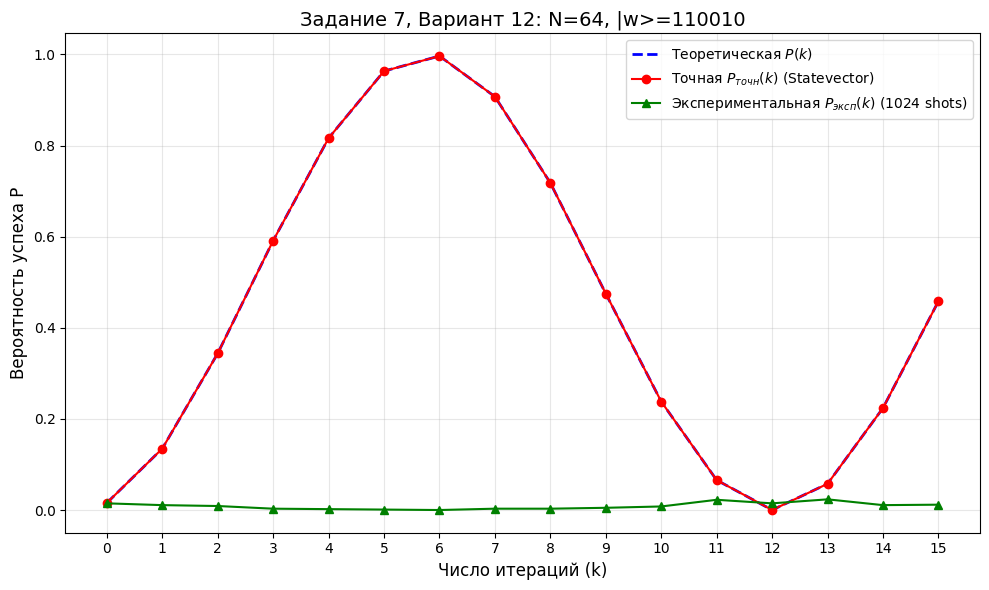


--- 7.2 Сводная таблица и оптимумы ---
Параметр             | Значение
-----------------------------------
Вариант              | 12
N                    | 64
|w>                  | 110010
k_теор (формула)     | 6
k_точн (максимум)    | 6
k_эксп (максимум)    | 13
max P_точн           | 0.996586
--- 7.4 Моделирование шума для Варианта 12 (N=64) ---

Моделирование при p2 = 0.005:
  Оптимальное k при шуме: 9
  Максимальная P при шуме: 0.0186
  Снижение максимума P: 0.9780

Моделирование при p2 = 0.02:
  Оптимальное k при шуме: 2
  Максимальная P при шуме: 0.0234
  Снижение максимума P: 0.9731

Объяснение влияния шума:
Шум на двухкубитных вентилях (CX) накапливается с каждой итерацией. 
Поскольку каждая итерация Гровера содержит много CX-вентилей (особенно 
после транспиляции многоконтрольных вентилей), с ростом k вероятность 
ошибки экспоненциально растет. Это приводит к двум эффектам:
1. Максимальная вероятность успеха P_max значительно снижается.
2. Оптимум k_опт смещается в сторону м

In [10]:
# Задание 7: Алгоритм Гровера — Вариант 12
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

print("ЗАДАНИЕ 7: АЛГОРИТМ ГРОВЕРА — ВАРИАНТ 12")

# Параметры варианта 12

variant = 12
n = 6                          # Количество кубитов
N = 2**n                       # Размер базы (64)
marked_str = "110010"          # Отмеченное состояние |w>
marked_int = int(marked_str, 2)# Целочисленное представление (50)
theta = np.arcsin(1 / np.sqrt(N)) # Угол поворота

print(f"Вариант: {variant}")
print(f"Количество кубитов (n): {n}")
print(f"Размер базы (N = 2^n): {N}")
print(f"Отмеченное состояние |w>: |{marked_str}> (индекс {marked_int})")
print(f"Угол theta = arcsin(1/sqrt(N)): {theta:.6f} рад\n")


# Функции для построения схем (из Задания 4)

def build_oracle(n, marked_str):
    """Фазовый оракул U_w"""
    qc = QuantumCircuit(n)
    bits = [(int(marked_str, 2) >> i) & 1 for i in range(n)]

    # Инвертируем кубиты, которые равны 0 в отмеченном состоянии
    for i in range(n):
        if bits[i] == 0:
            qc.x(i)

    # Многоконтрольный Z (через H и MCX)
    qc.h(n-1)
    qc.mcx(list(range(n-1)), n-1)
    qc.h(n-1)

    # Обратные инверсии
    for i in range(n):
        if bits[i] == 0:
            qc.x(i)
    return qc

def build_diffuser(n):
    """Инверсия относительно среднего U_s"""
    qc = QuantumCircuit(n)
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n-1)
    qc.mcx(list(range(n-1)), n-1)
    qc.h(n-1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

def get_grover_circuit(n, marked_str, k):
    """Сборка полной схемы Гровера с k итерациями"""
    qc = QuantumCircuit(n, n)
    qc.h(range(n))

    oracle = build_oracle(n, marked_str)
    diffuser = build_diffuser(n)

    for _ in range(k):
        qc.compose(oracle, inplace=True)
        qc.compose(diffuser, inplace=True)

    qc.measure(range(n), range(n))
    return qc

def get_exact_statevector_circuit(n, marked_str, k):
    """Схема без измерений для получения точного Statevector"""
    qc = QuantumCircuit(n)
    qc.h(range(n))
    oracle = build_oracle(n, marked_str)
    diffuser = build_diffuser(n)
    for _ in range(k):
        qc.compose(oracle, inplace=True)
        qc.compose(diffuser, inplace=True)
    return qc


# 7.1 Точные и экспериментальные вероятности для k = 0..15

print("--- 7.1 Вычисление вероятностей P(k) для k = 0..15 ---")

k_values = list(range(16))
P_theory = []
P_exact = []
P_exp = []

shots = 1024
sim = AerSimulator()

for k in k_values:
    # 1. Теоретическая вероятность
    p_th = np.sin((2 * k + 1) * theta)**2
    P_theory.append(p_th)

    # 2. Точная вероятность (через Statevector)
    qc_sv = get_exact_statevector_circuit(n, marked_str, k)
    sv = Statevector(qc_sv)
    p_ex = np.abs(sv.data[marked_int])**2
    P_exact.append(p_ex)

    # 3. Экспериментальная вероятность (через симулятор с выборкой)
    qc_meas = get_grover_circuit(n, marked_str, k)
    result = sim.run(qc_meas, shots=shots).result()
    counts = result.get_counts()
    # Qiskit использует little-endian порядок битов в строках ключей
    key = format(marked_int, f'0{n}b')[::-1]
    p_exp_val = counts.get(key, 0) / shots
    P_exp.append(p_exp_val)

# Построение графиков
plt.figure(figsize=(10, 6))
plt.plot(k_values, P_theory, 'b--', label='Теоретическая $P(k)$', linewidth=2)
plt.plot(k_values, P_exact, 'ro-', label='Точная $P_{точн}(k)$ (Statevector)', markersize=6)
plt.plot(k_values, P_exp, 'g^-', label='Экспериментальная $P_{эксп}(k)$ (1024 shots)', markersize=6)
plt.xlabel('Число итераций (k)', fontsize=12)
plt.ylabel('Вероятность успеха P', fontsize=12)
plt.title(f'Задание 7, Вариант 12: N={N}, |w>={marked_str}', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(k_values)
plt.tight_layout()
plt.show()


# 7.2 Сводная таблица и оптимальное число итераций

print("\n--- 7.2 Сводная таблица и оптимумы ---")

k_theor = int(np.floor((np.pi / 4) * np.sqrt(N)))
k_exact_max = int(np.argmax(P_exact))
k_exp_max = int(np.argmax(P_exp))
max_p_exact = max(P_exact)

print(f"{'Параметр':<20} | {'Значение'}")
print("-" * 35)
print(f"{'Вариант':<20} | {variant}")
print(f"{'N':<20} | {N}")
print(f"{'|w>':<20} | {marked_str}")
print(f"{'k_теор (формула)':<20} | {k_theor}")
print(f"{'k_точн (максимум)':<20} | {k_exact_max}")
print(f"{'k_эксп (максимум)':<20} | {k_exp_max}")
print(f"{'max P_точн':<20} | {max_p_exact:.6f}")

# 7.4 Моделирование шума (Адаптировано для Варианта 12: N=2^6)

print("--- 7.4 Моделирование шума для Варианта 12 (N=64) ---")

p2_values = [0.005, 0.02]
basis_gates = ['cx', 'u1', 'u2', 'u3'] # Базис для транспиляции

for p2 in p2_values:
    print(f"\nМоделирование при p2 = {p2}:")
    P_noisy = []

    for k in k_values:
        noise_model = NoiseModel()
        error_2q = depolarizing_error(p2, 2)
        noise_model.add_all_qubit_quantum_error(error_2q, ['cx', 'cz', 'swap'])

        qc_meas = get_grover_circuit(n, marked_str, k)
        # Транспиляция схемы в базис симулятора (CCX разбивается на CX)
        qc_transpiled = transpile(qc_meas, basis_gates=basis_gates)

        sim_noisy = AerSimulator(noise_model=noise_model)
        result = sim_noisy.run(qc_transpiled, shots=shots).result()
        counts = result.get_counts()

        key = format(marked_int, f'0{n}b')[::-1]
        p_noisy = counts.get(key, 0) / shots
        P_noisy.append(p_noisy)

    k_noisy_max = int(np.argmax(P_noisy))
    max_p_noisy = max(P_noisy)

    print(f"  Оптимальное k при шуме: {k_noisy_max}")
    print(f"  Максимальная P при шуме: {max_p_noisy:.4f}")
    print(f"  Снижение максимума P: {max_p_exact - max_p_noisy:.4f}")

print("""
Объяснение влияния шума:
Шум на двухкубитных вентилях (CX) накапливается с каждой итерацией.
Поскольку каждая итерация Гровера содержит много CX-вентилей (особенно
после транспиляции многоконтрольных вентилей), с ростом k вероятность
ошибки экспоненциально растет. Это приводит к двум эффектам:
1. Максимальная вероятность успеха P_max значительно снижается.
2. Оптимум k_опт смещается в сторону меньших значений (оптимально
   останавливать алгоритм раньше, пока шум не разрушил квантовую
   суперпозицию). Глубина схемы напрямую определяет устойчивость к шуму.
""")